In [3]:
import numpy as np
import pandas as pd


In [4]:
dataFrame=pd.read_excel("bisiklet_fiyatlari.xlsx")

In [5]:
dataFrame.head()

,Fiyat,BisikletOzellik1,BisikletOzellik2
0,807.673876,1749.628226,1749.590668
1,959.227520,1748.007826,1751.824206
2,718.020033,1750.122967,1747.977026
3,945.668885,1749.916440,1750.771646
4,955.542968,1750.780519,1750.592430


In [6]:
import seaborn as sbn
import matplotlib.pyplot as plt

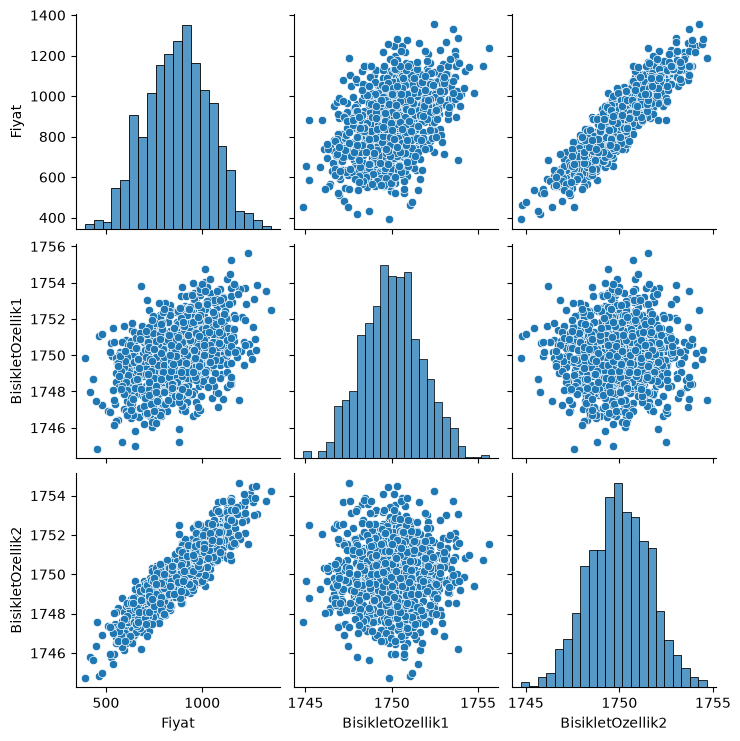

In [7]:
sbn.pairplot(dataFrame) 


In [8]:
##veriyi test/train olarak ikiye ayırmak

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
#train_test_split
dataFrame

,Fiyat,BisikletOzellik1,BisikletOzellik2
0,807.673876,1749.628226,1749.590668
1,959.227520,1748.007826,1751.824206
2,718.020033,1750.122967,1747.977026
3,945.668885,1749.916440,1750.771646
4,955.542968,1750.780519,1750.592430
...,...,...,...
995,833.920637,1750.033229,1749.427281
996,800.298076,1747.996913,1750.035046
997,799.261737,1752.540381,1747.983310
998,705.802257,1751.349290,1747.484989


In [11]:
#y = wx + b
#y -> label 
y = dataFrame["Fiyat"].values

#x -> feature (özellik)
x = dataFrame[["BisikletOzellik1","BisikletOzellik2"]].values

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.33,random_state=15)

In [12]:
x_train.shape

(670, 2)

In [13]:
x_test.shape

(330, 2)

In [14]:
y_train.shape

(670,)

In [15]:
y_test.shape

(330,)

In [16]:
#scaling 
from sklearn.preprocessing import MinMaxScaler

In [17]:
scaler = MinMaxScaler()

In [18]:
scaler.fit(x_train)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](2,)","[1755.61,1754.67]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](2,)","[1745. ,1744.99]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](2,)","[10.61, 9.67]"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](2,)","[-164.44,-180.42]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,670
"scale_ scale_: ndarray of shape (n_features,)Per feature relative scaling of the data. Equivalent to``(max - min) / (X.max(axis=0) - X.min(axis=0))``.. versionadded:: 0.17 *scale_* attribute.","ndarray[float64](2,)","[0.09,0.1 ]"


In [19]:
x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

In [20]:
x_train

array([[0.3177906 , 0.64341466],
       [0.61991638, 0.89583174],
       [0.53950097, 0.0980286 ],
       ...,
       [0.2352117 , 0.52644765],
       [0.7576794 , 0.19157421],
       [0.4292982 , 0.16530301]], shape=(670, 2))

In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense  

In [22]:
model = Sequential()
model.add(Dense(4,activation="relu"))
model.add(Dense(4,activation="relu"))
model.add(Dense(4,activation="relu"))

model.add(Dense(1))

model.compile(optimizer= "rmsprop",loss="mse")


In [23]:
model.fit(x_train,y_train,epochs=250)

Epoch 1/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 795732.1250 
Epoch 2/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 795448.1875 
Epoch 3/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 795154.9375 
Epoch 4/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 794834.4375 
Epoch 5/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 794493.4375 
Epoch 6/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 794131.5625 
Epoch 7/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 793739.3750  
Epoch 8/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 793315.2500 
Epoch 9/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 792858.8750 
Epoch 10/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 792371.9375 
Epoch 11/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 791855.1875 
Epoch 12/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 791302.6875 
Epoch 13/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 790701.3750 
Epoch 14/250
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss

In [24]:
loss = model.history.history["loss"]
loss

[795732.125,
 795448.1875,
 795154.9375,
 794834.4375,
 794493.4375,
 794131.5625,
 793739.375,
 793315.25,
 792858.875,
 792371.9375,
 791855.1875,
 791302.6875,
 790701.375,
 790039.5,
 789305.25,
 788495.375,
 787608.0,
 786642.8125,
 785597.75,
 784469.5625,
 783254.125,
 781947.4375,
 780544.8125,
 779042.5625,
 777435.6875,
 775720.125,
 773891.5,
 771944.875,
 769875.9375,
 767680.1875,
 765352.625,
 762888.8125,
 760283.875,
 757533.0625,
 754631.75,
 751575.3125,
 748358.6875,
 744977.3125,
 741426.5625,
 737701.4375,
 733797.4375,
 729710.0625,
 725434.5625,
 720966.4375,
 716301.4375,
 711435.0625,
 706363.1875,
 701081.625,
 695586.125,
 689873.25,
 683938.9375,
 677779.75,
 671392.25,
 664773.3125,
 657919.875,
 650829.3125,
 643498.875,
 635926.4375,
 628110.0625,
 620048.1875,
 611739.0625,
 603182.0,
 594376.375,
 585321.8125,
 576018.4375,
 566466.75,
 556667.9375,
 546623.5625,
 536335.5,
 525806.25,
 515039.09375,
 504037.625,
 492806.4375,
 481350.21875,
 469674.875

<Axes: >

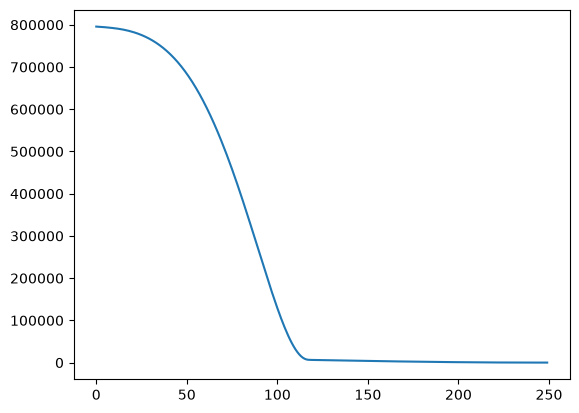

In [25]:
sbn.lineplot(x=range(len(loss)),y=loss)

In [26]:
trainLoss=model.evaluate(x_train,y_train, verbose=0)

In [27]:
testLoss = model.evaluate(x_test,y_test,verbose=0)

In [28]:
trainLoss

81.50202941894531

In [29]:
testLoss

85.63451385498047

In [30]:
testTahminleri = model.predict(x_test)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


In [31]:
tahminDF = pd.DataFrame(y_test,columns=["Gerçek Y"])

In [32]:
tahminDF 

,Gerçek Y
0,1081.652164
1,622.675990
2,889.356810
3,902.826733
4,897.662404
...,...
325,1028.438035
326,789.934950
327,758.490486
328,1172.871659


In [33]:
testTahminleri = pd.Series(testTahminleri.reshape(330,))

In [34]:
testTahminleri

0      1073.743896
1       625.835571
2       874.521606
3       894.254578
4       899.751099
          ...     
325    1010.051086
326     791.891052
327     765.682129
328    1161.795776
329     804.236511
Length: 330, dtype: float32

In [35]:
tahminDF = pd.concat([tahminDF,testTahminleri],axis=1)

In [36]:
tahminDF.columns = ["Gerçek Y","Tahmin Y"]

In [37]:
tahminDF

,Gerçek Y,Tahmin Y
0,1081.652164,1073.743896
1,622.675990,625.835571
2,889.356810,874.521606
3,902.826733,894.254578
4,897.662404,899.751099
...,...,...
325,1028.438035,1010.051086
326,789.934950,791.891052
327,758.490486,765.682129
328,1172.871659,1161.795776


<Axes: xlabel='Gerçek Y', ylabel='Tahmin Y'>

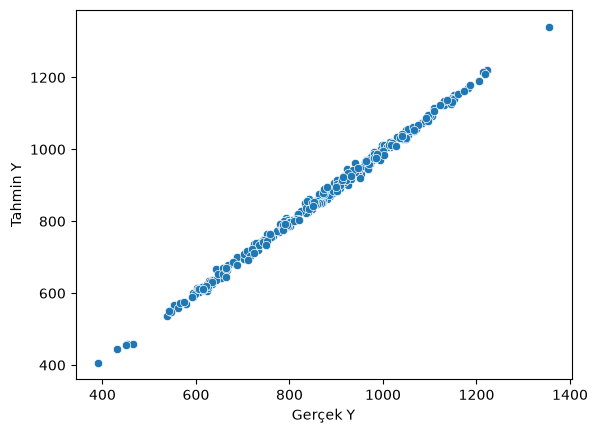

In [38]:
sbn.scatterplot(x = "Gerçek Y", y = "Tahmin Y", data= tahminDF)

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [40]:
mean_absolute_error(tahminDF["Gerçek Y"], tahminDF["Tahmin Y"])

7.441672958613871

In [41]:
mean_squared_error(tahminDF["Tahmin Y"],tahminDF["Gerçek Y"])

85.63452394605862

In [42]:
dataFrame.describe()

,Fiyat,BisikletOzellik1,BisikletOzellik2
count,1000.000000,1000.000000,1000.000000
mean,872.677801,1750.024800,1749.964733
std,164.124504,1.704531,1.659578
min,390.856887,1744.852108,1744.742389
25%,757.795031,1748.831119,1748.803186
50%,879.168705,1750.017350,1750.003926
75%,988.612778,1751.115765,1751.129414
max,1355.213745,1755.613884,1754.666038


In [46]:
yeniBisikletOzellikleri =[[1753,1751]]

In [47]:
yeniBisikletOzellikleri=scaler.transform(yeniBisikletOzellikleri)

In [49]:
model.predict(yeniBisikletOzellikleri)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


array([[1077.6993]], dtype=float32)

In [50]:
from tensorflow.keras.models import load_model

In [51]:
model.save("bisiklet_modeli.h5")

In [52]:
sonradanCagirilanModel = load_model("bisiklet_modeli.h5")

In [53]:
sonradanCagirilanModel.predict(yeniBisikletOzellikleri)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step


array([[1077.6993]], dtype=float32)